## Практика по работе с изображением — готовый ноутбук

В этом ноутбуке собраны все пять частей практикума:
1. Цветовые пространства
2. Выделение контуров (Contours)
3. Денойзинг
4. Морфология
5. Преобразования изображений

**Требования:** положите `img1.png` (три зелёных яблока) и `img2.png` (цветок крупным планом) в рабочую директорию ноутбука.

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

np.random.seed(42)  # воспроизводимость шума

def show(images, titles, figsize=(16, 5), gray_cmap='gray'):
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1: axes = [axes]
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap=gray_cmap)
        else:
            ax.imshow(im)
        ax.set_title(t, fontsize=11)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# ---------- Загрузка изображений ----------
img1 = cv2.imread('img1.png')   # 3 зелёных яблока
img2 = cv2.imread('img2.png')   # цветок крупным планом
if img1 is None or img2 is None:
    raise FileNotFoundError('Положите img1.png и img2.png рядом с ноутбуком')

img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

print('img1:', img1.shape, '| img2:', img2.shape)

img1: (850, 1332, 3) | img2: (417, 626, 3)


---
## 1. Цветовые пространства

Конвертируем RGB → HSV / LAB / YCrCb и обратно, затем сегментируем зелёные яблоки в HSV.

**Зачем нужны преобразования цветовых пространств:**
- **HSV** — тон (H) отделён от яркости (V), удобно для цветовой сегментации при разном освещении (поиск объектов по цвету, роботы-сортировщики, детекторы кожи).
- **LAB** — перцептивно равномерное пространство, L — светлота, a/b — цветовые оси. Используется в цветокоррекции, сравнении цветов, кластеризации (k-means), обучении нейросетей.
- **YCrCb** — яркость Y отделена от цветности Cr/Cb. Применяется в видеокодеках (JPEG, MPEG), детекции кожи, сжатии.

**Обратные преобразования без потерь** (ошибка ≈ 0) показывают, что пространства лишь переупаковывают информацию.

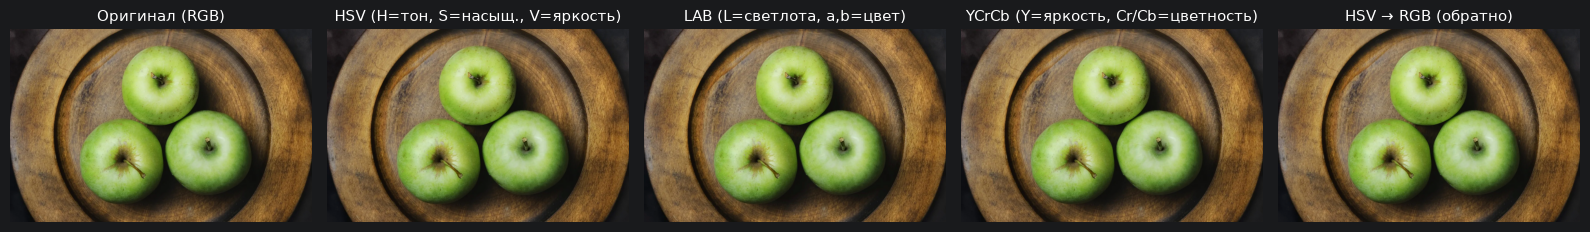

Средняя ошибка HSV → RGB: 0.3783501148207031 (≈0 → преобразование без потерь)


In [9]:
# ---------- 1.1 RGB → HSV → RGB ----------
hsv      = cv2.cvtColor(img1, cv2.COLOR_BGR2HSV)
hsv_back = cv2.cvtColor(hsv,  cv2.COLOR_HSV2BGR)

# ---------- 1.2 RGB → LAB → RGB ----------
lab      = cv2.cvtColor(img1, cv2.COLOR_BGR2LAB)
lab_back = cv2.cvtColor(lab,  cv2.COLOR_LAB2BGR)

# ---------- 1.3 RGB → YCrCb → RGB ----------
ycrcb      = cv2.cvtColor(img1, cv2.COLOR_BGR2YCrCb)
ycrcb_back = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)

show([img1_rgb,
      cv2.cvtColor(hsv,   cv2.COLOR_HSV2RGB),
      cv2.cvtColor(lab,   cv2.COLOR_LAB2RGB),
      cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB),
      cv2.cvtColor(hsv_back, cv2.COLOR_BGR2RGB)],
     ['Оригинал (RGB)',
      'HSV (H=тон, S=насыщ., V=яркость)',
      'LAB (L=светлота, a,b=цвет)',
      'YCrCb (Y=яркость, Cr/Cb=цветность)',
      'HSV → RGB (обратно)'])

diff_hsv = np.abs(img1.astype(int) - hsv_back.astype(int)).mean()
print('Средняя ошибка HSV → RGB:', diff_hsv, '(≈0 → преобразование без потерь)')

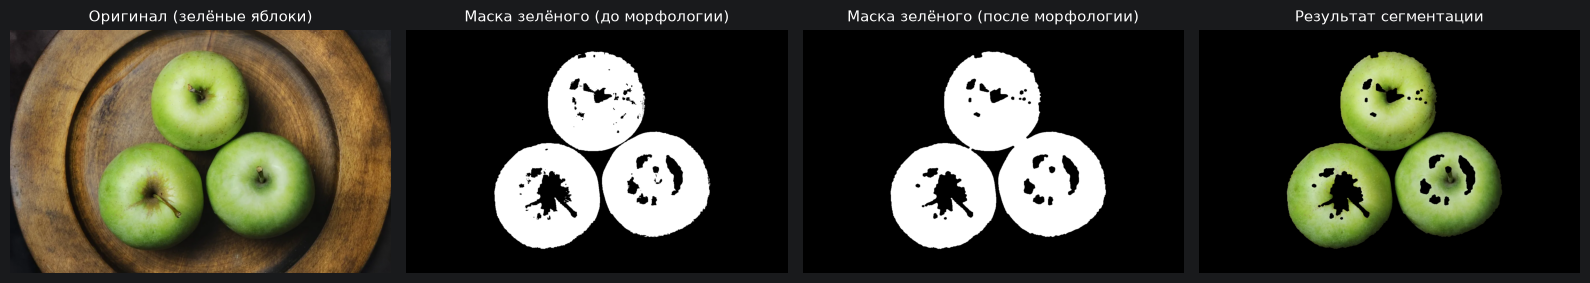

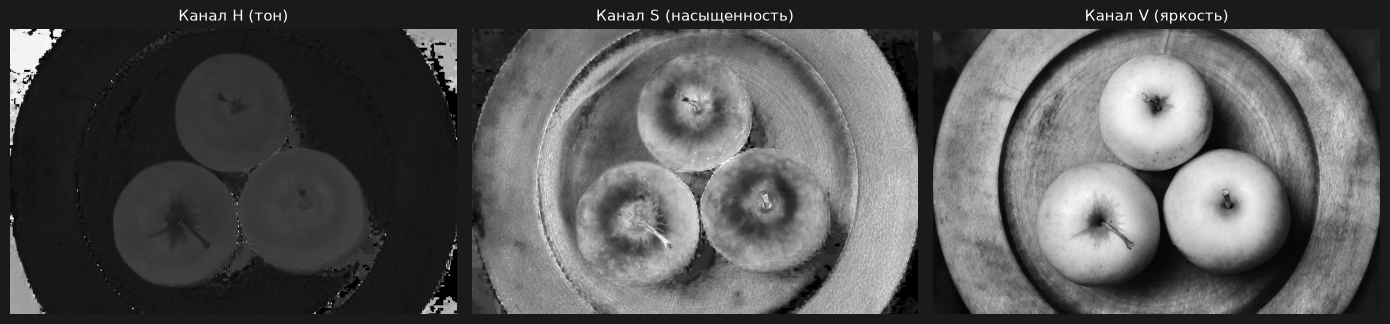

In [10]:
# ---------- 1.4 Сегментация ЗЕЛЁНЫХ яблок в HSV ----------
# OpenCV: H ∈ [0,179]; зелёный ≈ 35..85
lower_green = np.array([35,  60,  40])
upper_green = np.array([85, 255, 255])

mask_raw = cv2.inRange(hsv, lower_green, upper_green)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN,  kernel, iterations=1)
mask = cv2.morphologyEx(mask,     cv2.MORPH_CLOSE, kernel, iterations=2)

segmented = cv2.bitwise_and(img1_rgb, img1_rgb, mask=mask)

h_ch, s_ch, v_ch = cv2.split(hsv)

show([img1_rgb, mask_raw, mask, segmented],
     ['Оригинал (зелёные яблоки)',
      'Маска зелёного (до морфологии)',
      'Маска зелёного (после морфологии)',
      'Результат сегментации'],
     figsize=(16, 4))

show([h_ch, s_ch, v_ch],
     ['Канал H (тон)', 'Канал S (насыщенность)', 'Канал V (яркость)'],
     figsize=(14, 4))

---
## 2. Выделение контуров (Contours)

**Методы и параметры:**
- `GaussianBlur (7×7)` — сглаживание шума перед бинаризацией.
- `Otsu + THRESH_BINARY_INV` — автоматический порог; инверсия, т.к. яблоки темнее фона.
- Морфология `CLOSE` (2 итерации) + `OPEN` (1 итерация) — устранение разрывов и мелкого шума в маске.
- `Canny(50,150)` — альтернативное детектирование краёв.
- `findContours(RETR_EXTERNAL, CHAIN_APPROX_SIMPLE)` + фильтр по площади (> 0.5% кадра).

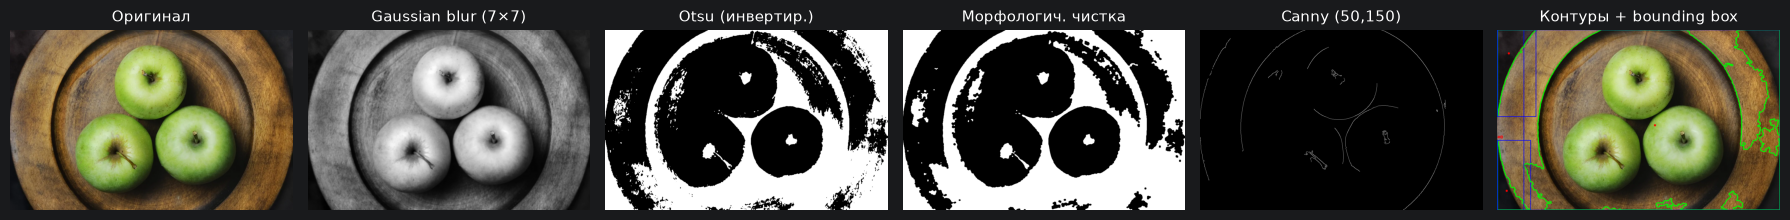

Найдено контуров после фильтрации: 3


In [11]:
# ---------- 2.1 Предобработка ----------
gray  = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
blur  = cv2.GaussianBlur(gray, (7, 7), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
clean  = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
clean  = cv2.morphologyEx(clean, cv2.MORPH_OPEN,  kernel, iterations=1)

# ---------- 2.2 Canny ----------
edges = cv2.Canny(blur, 50, 150)

# ---------- 2.3 Контуры ----------
contours, hierarchy = cv2.findContours(clean, cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)
area_img = gray.shape[0] * gray.shape[1]
big = [c for c in contours if cv2.contourArea(c) > 0.005 * area_img]

vis = img1.copy()
for i, c in enumerate(big):
    cv2.drawContours(vis, [c], -1, (0, 255, 0), 3)
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
    M = cv2.moments(c)
    if M['m00'] > 0:
        cx, cy = int(M['m10'] / M['m00']), int(M['m01'] / M['m00'])
        cv2.circle(vis, (cx, cy), 5, (0, 0, 255), -1)
        cv2.putText(vis, f'#{i}', (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX,
                    0.7, (0, 0, 255), 2)

show([cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), blur, thresh, clean,
      edges, cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)],
     ['Оригинал', 'Gaussian blur (7×7)', 'Otsu (инвертир.)',
      'Морфологич. чистка', 'Canny (50,150)', 'Контуры + bounding box'],
     figsize=(18, 4))
print(f'Найдено контуров после фильтрации: {len(big)}')

---
## 3. Денойзинг

Добавляем **гауссов шум** (σ=25) и **соль-перец** (4%), затем сравниваем:
- **Gaussian blur** — хорошо давит гауссов шум, но размывает края.
- **Median blur** — идеален для соли-перца, сохраняет края.
- **Bilateral** — сглаживает, сохраняя границы (края).
- **NLM (fastNlMeans)** — лучшее сохранение текстур, но медленнее.

Метрики: **PSNR** (выше = лучше) и **SSIM** (ближе к 1 = лучше).

=== Шум Гаусса (σ=25) ===
Метод           PSNR    SSIM
Gaussian       25.75  0.7747
Median         24.81  0.7734
Bilateral      27.32  0.7982
NLM            24.09  0.6743

=== Соль и перец (4%) ===
Метод           PSNR    SSIM
Gaussian       25.38  0.7314
Median         26.04  0.9011
Bilateral      18.50  0.5076
NLM            18.64  0.5185


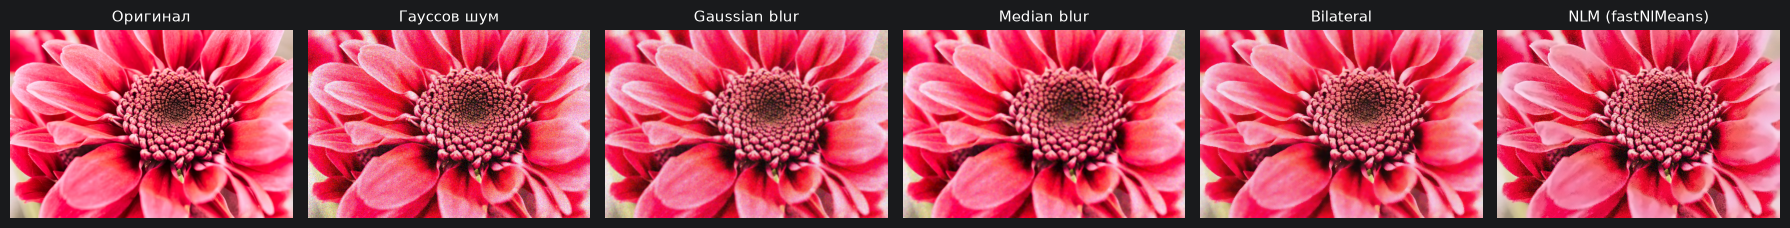

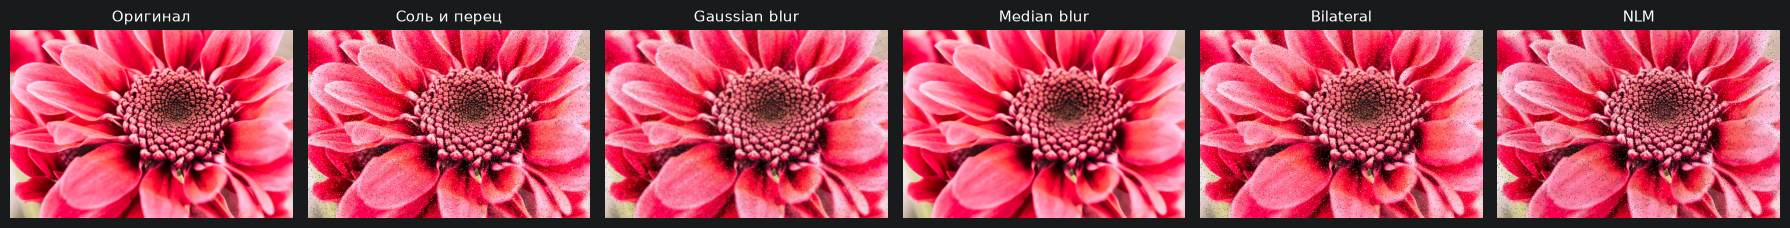

In [12]:
# ---------- 3.1 Шум ----------
def add_gaussian_noise(img, sigma=25):
    noise = np.random.normal(0, sigma, img.shape).astype(np.float32)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def add_salt_pepper(img, amount=0.03):
    out = img.copy()
    n = int(amount * img.shape[0] * img.shape[1])
    ys = np.random.randint(0, img.shape[0], n)
    xs = np.random.randint(0, img.shape[1], n)
    out[ys[:n//2], xs[:n//2]] = 255
    out[ys[n//2:], xs[n//2:]] = 0
    return out

clean_img = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
noisy_g   = add_gaussian_noise(clean_img, sigma=25)
noisy_sp  = add_salt_pepper(clean_img, amount=0.04)

# ---------- 3.2 Денойзинг ----------
def denoise_all(noisy):
    return {
        'Gaussian' : cv2.GaussianBlur(noisy, (5, 5), 0),
        'Median'   : cv2.medianBlur(noisy, 5),
        'Bilateral': cv2.bilateralFilter(noisy, 9, 75, 75),
        'NLM'      : cv2.fastNlMeansDenoisingColored(noisy, None, 10, 10, 7, 21)
    }

res_g  = denoise_all(noisy_g)
res_sp = denoise_all(noisy_sp)

# ---------- 3.3 Оценка ----------
def score(ref, test):
    p = psnr(ref, test)
    s = ssim(ref, test, channel_axis=2, data_range=255)
    return p, s

print('=== Шум Гаусса (σ=25) ===')
print(f"{'Метод':<12}{'PSNR':>8}{'SSIM':>8}")
for name, im in res_g.items():
    p, s = score(clean_img, im)
    print(f'{name:<12}{p:8.2f}{s:8.4f}')

print('\n=== Соль и перец (4%) ===')
print(f"{'Метод':<12}{'PSNR':>8}{'SSIM':>8}")
for name, im in res_sp.items():
    p, s = score(clean_img, im)
    print(f'{name:<12}{p:8.2f}{s:8.4f}')

show([clean_img, noisy_g, res_g['Gaussian'], res_g['Median'],
      res_g['Bilateral'], res_g['NLM']],
     ['Оригинал', 'Гауссов шум', 'Gaussian blur', 'Median blur',
      'Bilateral', 'NLM (fastNlMeans)'], figsize=(18, 4))

show([clean_img, noisy_sp, res_sp['Gaussian'], res_sp['Median'],
      res_sp['Bilateral'], res_sp['NLM']],
     ['Оригинал', 'Соль и перец', 'Gaussian blur', 'Median blur',
      'Bilateral', 'NLM'], figsize=(18, 4))

---
## 4. Морфология

Операции над бинарной маской:
- **Erosion** — уменьшает объекты, убирает мелкий шум.
- **Dilation** — расширяет объекты, заполняет разрывы.
- **Opening** (erode→dilate) — удаляет мелкие объекты, сохраняя форму крупных.
- **Closing** (dilate→erode) — заделывает дыры внутри объектов.
- **Gradient** (dilate−erode) — контур объектов.
- **TopHat** (orig−opening) — выделяет мелкие светлые детали.
- **BlackHat** (closing−orig) — выделяет мелкие тёмные детали.

**Как морфология улучшает контуры:** убирает шум в маске → `findContours` находит меньше ложных контуров и даёт более чистые границы объектов.

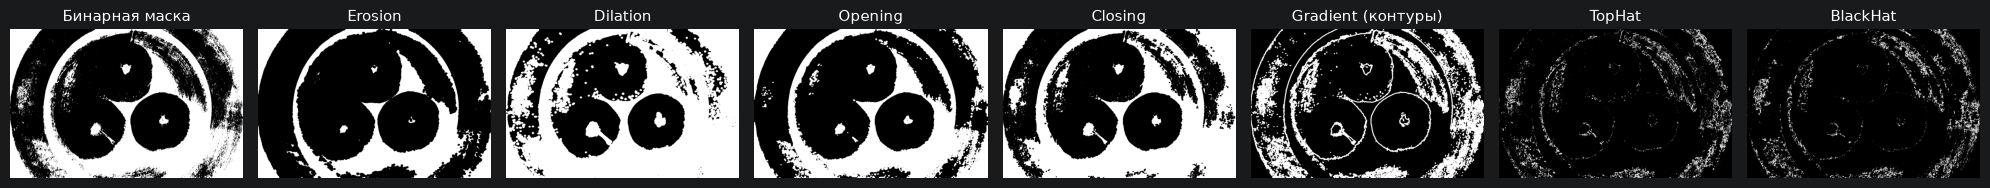

Контуров без морфологии: 1383
Контуров после морфологии: 14


In [13]:
gray1  = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
_, binmask = cv2.threshold(gray1, 0, 255,
                           cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

erode    = cv2.erode(binmask,  k, iterations=2)
dilate   = cv2.dilate(binmask, k, iterations=2)
opening  = cv2.morphologyEx(binmask, cv2.MORPH_OPEN,     k)
closing  = cv2.morphologyEx(binmask, cv2.MORPH_CLOSE,    k)
grad     = cv2.morphologyEx(binmask, cv2.MORPH_GRADIENT, k)
tophat   = cv2.morphologyEx(binmask, cv2.MORPH_TOPHAT,   k)
blackhat = cv2.morphologyEx(binmask, cv2.MORPH_BLACKHAT, k)

show([binmask, erode, dilate, opening, closing, grad, tophat, blackhat],
     ['Бинарная маска', 'Erosion', 'Dilation', 'Opening', 'Closing',
      'Gradient (контуры)', 'TopHat', 'BlackHat'],
     figsize=(20, 5), gray_cmap='gray')

raw_cnts, _ = cv2.findContours(binmask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
clean_mask  = cv2.morphologyEx(binmask, cv2.MORPH_OPEN,  k, iterations=2)
clean_mask  = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, k, iterations=2)
clean_cnts, _ = cv2.findContours(clean_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f'Контуров без морфологии: {len(raw_cnts)}')
print(f'Контуров после морфологии: {len(clean_cnts)}')

---
## 5. Преобразования изображений

**Геометрия:** поворот (`getRotationMatrix2D` + `warpAffine`), масштаб (`resize` с разными интерполяциями: CUBIC — увеличение, AREA — уменьшение), сдвиг (аффинная матрица).

**Яркость/контраст/гамма:** `convertScaleAbs(α, β)` — линейное преобразование `out = α·in + β`; гамма-коррекция — нелинейное изменение яркости.

**Фильтрация:** Gaussian (размытие), Median (шум), Sobel X / Laplacian (края).

**Зачем в предобработке:** аугментация данных для нейросетей, нормализация освещения, повышение контраста, выделение границ перед детекторами/сегментацией, устранение шума.

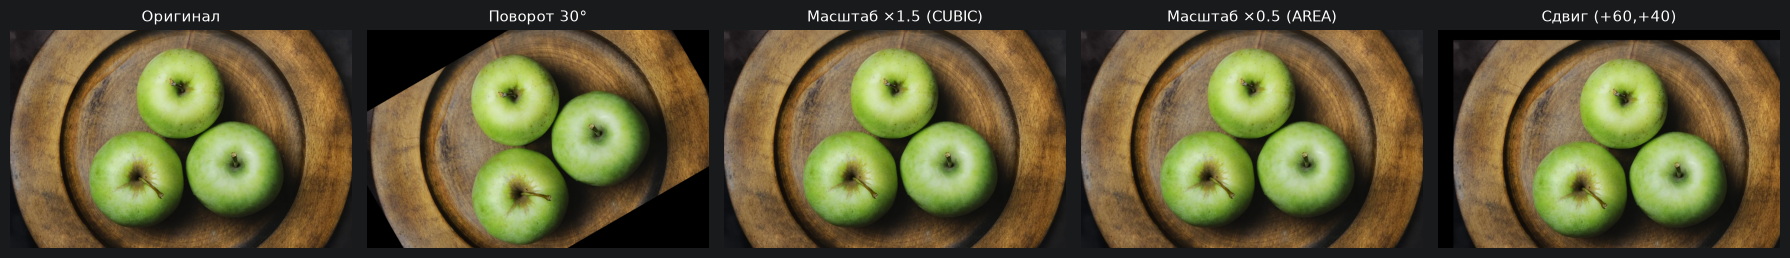

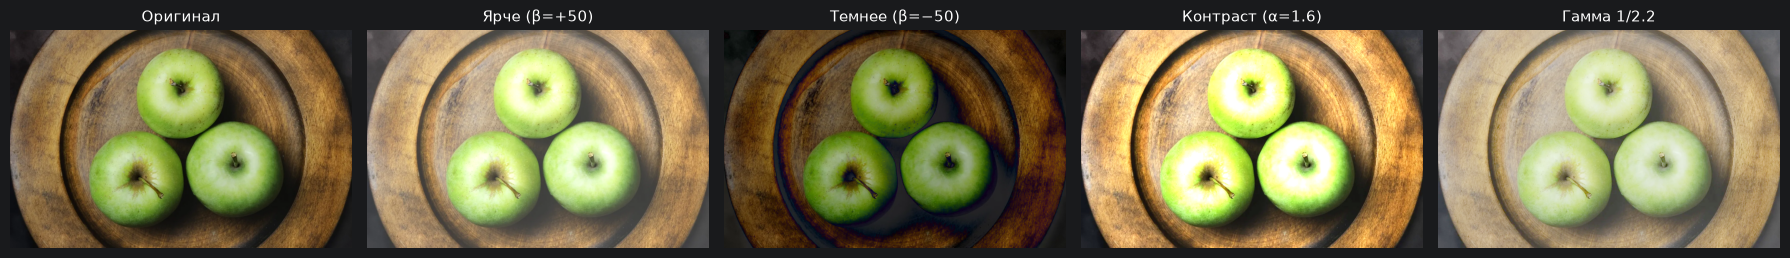

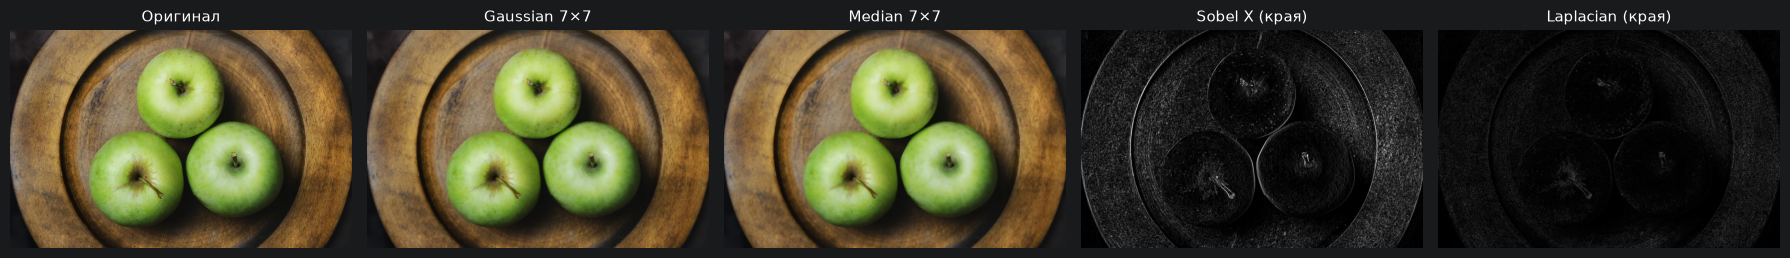

In [14]:
h, w = img1.shape[:2]
img = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

# ---------- 5.1 Поворот ----------
M_rot = cv2.getRotationMatrix2D((w/2, h/2), angle=30, scale=1.0)
rotated = cv2.warpAffine(img, M_rot, (w, h),
                         flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=(0,0,0))

# ---------- 5.2 Масштабирование ----------
scaled_up   = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
scaled_down = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

# ---------- 5.3 Сдвиг ----------
M_shift = np.float32([[1, 0, 60], [0, 1, 40]])
shifted = cv2.warpAffine(img, M_shift, (w, h))

# ---------- 5.4 Яркость / контраст / гамма ----------
bright   = cv2.convertScaleAbs(img, alpha=1.0, beta=50)
dark     = cv2.convertScaleAbs(img, alpha=1.0, beta=-50)
contrast = cv2.convertScaleAbs(img, alpha=1.6, beta=0)
gamma    = (np.power(img/255.0, 1/2.2) * 255).astype(np.uint8)

# ---------- 5.5 Фильтрация ----------
gauss   = cv2.GaussianBlur(img, (7, 7), 0)
median  = cv2.medianBlur(img, 7)
sobel_x = cv2.convertScaleAbs(
    cv2.Sobel(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), cv2.CV_64F, 1, 0, ksize=3))
lap     = cv2.convertScaleAbs(
    cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), cv2.CV_64F))

show([img, rotated, scaled_up, scaled_down, shifted],
     ['Оригинал', 'Поворот 30°', 'Масштаб ×1.5 (CUBIC)',
      'Масштаб ×0.5 (AREA)', 'Сдвиг (+60,+40)'], figsize=(18, 4))

show([img, bright, dark, contrast, gamma],
     ['Оригинал', 'Ярче (β=+50)', 'Темнее (β=−50)',
      'Контраст (α=1.6)', 'Гамма 1/2.2'], figsize=(18, 4))

show([img, gauss, median, sobel_x, lap],
     ['Оригинал', 'Gaussian 7×7', 'Median 7×7',
      'Sobel X (края)', 'Laplacian (края)'], figsize=(18, 4))

---
## Выводы

1. **Цветовые пространства** позволяют отделить информацию о цвете от яркости. HSV удобно для цветовой сегментации (зелёные яблоки выделены по H∈[35,85]), LAB — для перцептивных задач, YCrCb — для видео/детекции кожи.
2. **Контуры** лучше всего выделяются после сглаживания + Otsu + морфологической чистки: число ложных контуров падает, границы становятся гладкими.
3. **Денойзинг:** Median — победитель по соли-перцу; NLM и Bilateral лучше сохраняют текстуры при гауссовом шуме; Gaussian blur проигрывает по SSIM из-за размытия краёв.
4. **Морфология** — ключевой инструмент чистки масок: Opening убирает мелкий шум, Closing — дыры; Gradient даёт контур объектов.
5. **Преобразования** нужны для аугментации, нормализации освещения, повышения контраста и выделения краёв — это стандартная предобработка перед детекцией/классификацией.